In [50]:
import concurrent.futures
import http.client
import time

import urllib.error
from urllib.parse import urlencode

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.table import Table
from astropy.visualization import quantity_support
from astropy.wcs import WCS

from astroquery.ipac.irsa import Irsa
from astroquery.simbad import Simbad


from pathlib import Path
import hashlib


# Suppress logging temporarily to prevent astropy
# from repeatedly printing out warning notices related to alternate WCSs
import logging
logging.getLogger('astropy').setLevel(logging.ERROR)

# The time it takes to read SPHEREx files can exceed
# astropy's default timeout limit. Increase it.
from astropy.utils.data import conf
conf.remote_timeout = 120

# Let matplotlib recognize astropy Quantities and auto-label axes with their units.
quantity_support()

<astropy.visualization.units.quantity_support.<locals>.MplQuantityConverterFormatted at 0x34e375130>

In [51]:
# Query corrdinate of 5 target from SIMBAD
centers = {
    'WISE_0855': {
        'ra_deg': 133.78948309791494,
        'dec_deg': -7.24294039128244
    }
}

TARGET_ALIASES = {
    'Barnards_Star': ["Barnard's Star", 'GJ 699'],
    'Epsilon_Indi_B': ['eps Ind B', 'epsilon Indi B', 'eps Ind Ba'],
    'RW_Aurigae': ['RW Aur'],
    'R_Draconis': ['R Dra']
}

simbad = Simbad()
simbad.server = 'simbad.harvard.edu' # 原來的掛了

for target, aliases in TARGET_ALIASES.items():
    center = None
    for name in aliases:
        try:
            result = simbad.query_object(name)
            if result is None or len(result) == 0:
                continue
                
            ra_col = 'ra' if 'ra' in result.colnames else 'RA'
            dec_col = 'dec' if 'dec' in result.colnames else 'DEC'
            
            try:
                center = SkyCoord(float(result[ra_col][0])*u.deg, float(result[dec_col][0])*u.deg, frame='icrs')
            except (TypeError, ValueError):
                center = SkyCoord(str(result[ra_col][0]), str(result[dec_col][0]), unit=(u.hourangle, u.deg), frame='icrs')
            break
            
        except Exception as exc:
            print(f'{target}, {name}: {exc}')

    if center is None:
        raise RuntimeError(f'Cannot find coordinates for {target}')

    centers[target] = {'ra_deg': center.ra.deg, 'dec_deg': center.dec.deg}

for target, center in centers.items():
    print(f'{target}: RA = {center["ra_deg"]:.8f}, Dec = {center["dec_deg"]:.8f}')


WISE_0855: RA = 133.78948310, Dec = -7.24294039
Barnards_Star: RA = 269.45207696, Dec = 4.69336497
Epsilon_Indi_B: RA = 331.04414659, Dec = -56.78284420
RW_Aurigae: RA = 76.95652603, Dec = 30.40143817
R_Draconis: RA = 248.16761083, Dec = 66.75497942


In [49]:
# 選擇要分析的資料

CUTOUT_SIZE = 0.1 * u.deg
DOWNLOAD_PARENT = Path(f'{CUTOUT_SIZE.to_value(u.arcmin):g}arcmin_spherex_targets').resolve()


TARGET_TO_ANALYZE = 'WISE_0855' # 'Barnards_Star', 'E'psilon_Indi_B', 'WISE_0855', 'RW_Aurigae', 'R_Draconis'
STACK_BAND_NUMBERS = [5, 6]
CROSS_BAND_MATCH_MAX_DAYS = 3.0
RUN_LABEL = 'v1'

ROOT = DOWNLOAD_PARENT / TARGET_TO_ANALYZE
manifest = Table.read(ROOT/'download_manifest.ecsv', format='ascii.ecsv')

all_records = [
    {'band': str(row['band']), 'mjd': float(row['mjd']), 'uri': str(row['uri']), 'path': str(row['path']), 'status': str(row['status'])}
    for row in manifest
]

usable = []

for record in all_records:
    if record['status'] not in ('downloaded', 'cached'):
        continue
    if not Path(record['path']).exists():
        continue
    usable.append(record)

usable.sort(key=lambda record: (record['mjd'], record['band']))


if not usable:
    raise RuntimeError('No usable FITS found')

position = centers[TARGET_TO_ANALYZE]
coord = SkyCoord(position['ra_deg']*u.deg, position['dec_deg']*u.deg, frame='icrs')
size = CUTOUT_SIZE
STACK_BANDS = tuple(f'SPHEREx-D{b}' for b in STACK_BAND_NUMBERS)

print(f'{TARGET_TO_ANALYZE}: {len(usable)}/{len(all_records)} usable FITS')
print('Stacking bands:', STACK_BANDS)


# sphereX每一個pixel前面還有加一個濾鏡 所以每個pixel看到的波長是不一樣的（線性漸變，相鄰的pixel還是很接近） 每次觀測source在不同pixel上 我們就可以看到不同的波長                         
def get_record_wave_wcs(hdul):
    wave_hdu = hdul['WCS-WAVE'].copy()
    wave_hdu.header['EXTNAME'] = 'WCS-WAVE'
    wave_hdu.header['EXTVER'] = 1
    temporary = fits.HDUList([fits.PrimaryHDU(), wave_hdu])
    spectral = WCS(hdul['IMAGE'].header, fobj=temporary, key='W')
    spectral.sip = None
    return spectral


WISE_0855: 251/258 usable FITS
Stacking bands: ('SPHEREx-D5', 'SPHEREx-D6')


Analysis: D5_D6_gap10_spaninf_v1
Output directory: 6arcmin_spherex_targets/RW_Aurigae/analysis_runs/D5_D6_gap10_spaninf_v1

========== TIME GROUPING SUMMARY ==========
Stacking bands: SPHEREx-D5, SPHEREx-D6
Total groups: 3
Group 01: MJD 60926.27514 - 60938.23206 | span=11.957 d | stack images=37 | all-band photometry images=74
Group 02: MJD 61091.71962 - 61108.21701 | span=16.497 d | stack images=38 | all-band photometry images=114
Group 03: MJD 61293.37847 - 61299.89590 | span=6.517 d | stack images=37 | all-band photometry images=97

All usable images: 335
Matched to groups: 285
Unmatched images: 50
Unmatched by band: {'SPHEREx-D1': 25, 'SPHEREx-D2': 0, 'SPHEREx-D3': 0, 'SPHEREx-D4': 25, 'SPHEREx-D5': 0, 'SPHEREx-D6': 0}
Group 1: stacked 37 images; median contributing images/pixel=37
Group 2: stacked 38 images; median contributing images/pixel=37
Group 3: stacked 37 images; median contributing images/pixel=37


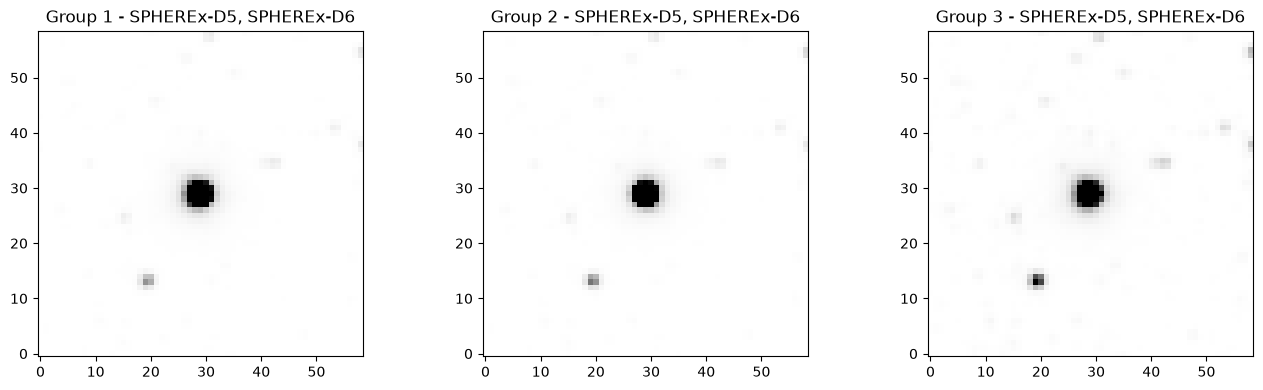

Saved 6arcmin_spherex_targets/RW_Aurigae/analysis_runs/D5_D6_gap10_spaninf_v1/time_grouped_stacks.fits


In [36]:
# Cell B - Time groups and broadband stacks

TIME_GAP_DAYS = 10.0  # 時間分組的最大相鄰間隔為 10 天
MAX_GROUP_SPAN_DAYS = float('inf')
MIN_COVERAGE = 0.9
BAD_FLAG_BITS = 0           # Set only after interpreting the bit-mask definitions.
SUBTRACT_BACKGROUND = True  # just for stacking, not for photometry

BAND_TAG = '_'.join(f'D{b}' for b in sorted(STACK_BAND_NUMBERS))
RUN_TAG = f'{BAND_TAG}_gap{TIME_GAP_DAYS:g}_span{MAX_GROUP_SPAN_DAYS:g}_{RUN_LABEL}'

RUN_DIR = ROOT / 'analysis_runs' / RUN_TAG
RUN_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FITS = RUN_DIR / 'time_grouped_stacks.fits'

print('Analysis:', RUN_TAG)
print('Output directory:', RUN_DIR)

def choose_time_splits(mjd, max_gap_days=2.0, max_span_days=5.0):  # 輸入一串依時間排序的 MJD，找出哪些位置應該切開，建立不同的觀測 Group。
    mjd = np.asarray(mjd, dtype=float)
    if not np.isfinite(mjd).all() or np.any(np.diff(mjd) < 0):
        raise ValueError('MJD must be finite and sorted')

    gaps = np.diff(mjd)
    cut_indices = []

    if len(mjd) > 0:
        group_start = mjd[0]
        for i, gap in enumerate(gaps):
            if gap > max_gap_days or mjd[i+1] - group_start > max_span_days:
                cut_indices.append(i)
                group_start = mjd[i+1]

    return np.asarray(cut_indices, dtype=int), float(max_gap_days), gaps

def resample_bilinear(image, variance, valid, native_wcs, sky, shape):
    
    sx, sy = native_wcs.world_to_pixel(sky)
    finite = np.isfinite(sx) & np.isfinite(sy)
    sx = np.where(finite, sx, -1e8).ravel()     # 如果座標有效，保留原始數值；如果無效，暫時改成 -1e8
    sy = np.where(finite, sy, -1e8).ravel()     # .ravel()： 將多維陣列攤平成一維。
    
    x0, y0 = np.floor(sx).astype(int), np.floor(sy).astype(int)
    fx, fy = sx - x0, sy - y0
    
    signal_sum = np.zeros(sx.size)
    weight_sum = np.zeros(sx.size)
    variance_sum = np.zeros(sx.size)
    ny, nx = image.shape
    # 四個格點的權重，用四個格點所以WCS座標對齊與轉換後的亮度分布最接近原本的
    for dx, dy, w in ( (0, 0, (1-fx)*(1-fy)), (1, 0, fx*(1-fy)), (0, 1, (1-fx)*fy), (1, 1, fx*fy) ):
        xx, yy = x0 + dx, y0 + dy
        idx = np.flatnonzero((xx >= 0) & (xx < nx) & (yy >= 0) & (yy < ny) & (w > 0))
        idx = idx[valid[yy[idx], xx[idx]]]
        signal_sum[idx] += w[idx] * image[yy[idx], xx[idx]]
        weight_sum[idx] += w[idx]                # 把周遭四個格點之中，valid的格點的權重相加，然後下面去看有沒有大於90%
        variance_sum[idx] += w[idx]**2 * variance[yy[idx], xx[idx]]
        
    good = weight_sum >= MIN_COVERAGE
    im, var = np.full(sx.size, np.nan), np.full(sx.size, np.nan)
    im[good] = signal_sum[good] / weight_sum[good]
    var[good] = variance_sum[good] / weight_sum[good]**2
    return im.reshape(shape), var.reshape(shape)


# ============================================================
# Time grouping: selected bandpasses ONLY.
# Other bands are assigned to the nearest selected-band epoch.
# ============================================================

selected_records = sorted([r for r in usable if r['band'] in STACK_BANDS and np.isfinite(r['mjd'])], key=lambda r: r['mjd'])

if not selected_records:
    raise RuntimeError(f'No observations or usable FITS for {STACK_BANDS}')

finite_times = np.array([r['mjd'] for r in selected_records], dtype=float)
cut_gaps, threshold, gaps = choose_time_splits(finite_times, TIME_GAP_DAYS, MAX_GROUP_SPAN_DAYS)  # 對 selected_records 所有的 mjd 來分組 
boundaries = np.array([(finite_times[i] + finite_times[i+1]) / 2 for i in cut_gaps], dtype=float)

# Reset group assignment every time Cell B runs.
for rec in all_records:
    rec['group'] = 0
    rec['delta_to_stack_days'] = np.nan

# Assign groups using ONLY the selected bandpasses.
for rec in selected_records:
    rec['group'] = 1 + int(np.searchsorted(boundaries, rec['mjd'], side='right'))  # side='right' 表示如果 MJD 剛好等於邊界，就分到右側的 Group。
    rec['delta_to_stack_days'] = 0.0

# Match other bandpasses to the nearest selected-band observation 
for rec in all_records:
    if rec['band'] in STACK_BANDS or not np.isfinite(rec['mjd']):
        continue

    t = rec['mjd']
    i = int(np.searchsorted(finite_times, t))
    candidates = [j for j in (i - 1, i) if 0 <= j < len(finite_times)]
    nearest = min(candidates, key=lambda j: abs(t - finite_times[j]))
    delta = abs(t - finite_times[nearest])
    rec['delta_to_stack_days'] = float(delta)

    if delta <= CROSS_BAND_MATCH_MAX_DAYS:
        rec['group'] = int(selected_records[nearest]['group'])

group_ids = sorted({r['group'] for r in selected_records})

'''
因為gif和stack image是用select records做出來的 所以在分組上也以select records為主 而不適用所有的record來分組
'''

print('\n========== TIME GROUPING SUMMARY ==========')
print('Stacking bands:', ', '.join(STACK_BANDS))
print('Total groups:', len(group_ids))

for g in group_ids:
    group_ref = [r for r in selected_records if r['group'] == g]
    group_stack = [r for r in selected_records if r['group'] == g]
    group_all = [r for r in usable if r['group'] == g]
    start, end = min(r['mjd'] for r in group_ref), max(r['mjd'] for r in group_ref)

    print(f'Group {g:02d}: MJD {start:.5f} - {end:.5f} | span={end-start:.3f} d | stack images={len(group_stack)} | all-band photometry images={len(group_all)}')
    assert end - start <= MAX_GROUP_SPAN_DAYS + 1e-7, f'Group {g} exceeds maximum span'

unmatched = [r for r in usable if r['group'] == 0]
print('\nAll usable images:', len(usable))
print('Matched to groups:', len(usable) - len(unmatched))
print('Unmatched images:', len(unmatched))
print('Unmatched by band:', {b: sum(r['band'] == b for r in unmatched) for b in sorted({r['band'] for r in all_records})})


# All groups share one celestial WCS reference grid.
ref_rec = selected_records[0]
with fits.open(ref_rec['path'], memmap=True) as h:
    ref_hdu = h['IMAGE']
    ref_wcs = WCS(ref_hdu.header).celestial
    shape = ref_hdu.data.shape
xx, yy = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
sky_grid = ref_wcs.pixel_to_world(xx, yy)

output_hdus = [fits.PrimaryHDU()]
for g in group_ids:
    members = [r for r in selected_records if r['group'] == g]
    numerator, denominator = np.zeros(shape), np.zeros(shape)
    contributions = np.zeros(shape, dtype=np.uint16)
    for rec in members:
        with fits.open(rec['path'], memmap=True) as h:
            image_hdu = h['IMAGE']
            im = np.asarray(image_hdu.data, dtype=float)
            var = np.asarray(h['VARIANCE'].data, dtype=float)
            valid = np.isfinite(im) & np.isfinite(var) & (var > 0)
            if BAD_FLAG_BITS:
                flags = np.asarray(h['FLAGS'].data, dtype=np.int64)
                valid &= (flags & BAD_FLAG_BITS) == 0
            if not valid.any():
                continue
            if SUBTRACT_BACKGROUND:
                im = im - np.median(im[valid])
            aligned, aligned_var = resample_bilinear(im, var, valid, WCS(image_hdu.header).celestial, sky_grid, shape)
            ok = np.isfinite(aligned) & np.isfinite(aligned_var) & (aligned_var > 0)
            numerator[ok] += aligned[ok] / aligned_var[ok]
            denominator[ok] += 1 / aligned_var[ok]
            contributions[ok] += 1
    stack, stack_var = np.full(shape, np.nan), np.full(shape, np.nan)
    good = denominator > 0
    stack[good], stack_var[good] = numerator[good] / denominator[good], 1 / denominator[good]
    times = [r['mjd'] for r in selected_records if r['group'] == g]
    header = ref_wcs.to_header(relax=True)
    header['MJDSTART'], header['MJDEND'], header['NINPUT'] = min(times), max(times), len(members)
    header['COMMENT'] = 'Cross-band stack for detection only; NOT a physical SED.'
    output_hdus.extend([fits.ImageHDU(stack.astype('f4'), header=header, name=f'STACK{g}'), fits.ImageHDU(stack_var.astype('f4'), header=header, name=f'VARIANCE{g}'), fits.ImageHDU(contributions, header=header, name=f'NCONTRIB{g}')])
    print(f'Group {g}: stacked {len(members)} images; median contributing images/pixel={np.median(contributions):.0f}')

fits.HDUList(output_hdus).writeto(OUTPUT_FITS, overwrite=True)
print('Saved', OUTPUT_FITS)

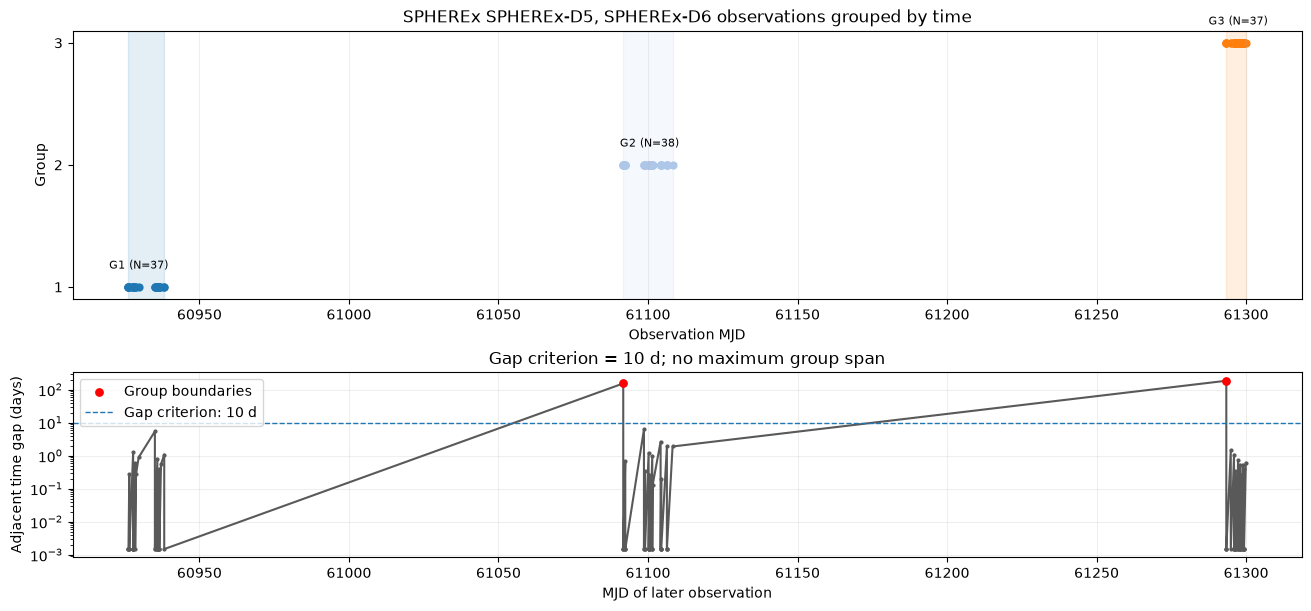

Saved grouping plot: 6arcmin_spherex_targets/RW_Aurigae/analysis_runs/D5_D6_gap10_spaninf_v1/time_grouping_diagnostic.png
Total groups: 3


In [37]:
# Cell B1: Plot observations grouped by time.
import matplotlib.pyplot as plt

all_groups = group_ids
color_map = plt.get_cmap('tab20')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, max(6, 5 + 0.18 * len(all_groups))), gridspec_kw={'height_ratios': [1.45, 1]}, constrained_layout=True)

for gid in all_groups:
    members = [r for r in selected_records if r['group'] == gid]
    times = np.array([r['mjd'] for r in members], float)
    success = np.array([r['status'] in ('downloaded', 'cached', 'reused') for r in members], bool)
    color = color_map((gid - 1) % 20)

    ax1.axvspan(times.min(), times.max(), color=color, alpha=0.12)
    ax1.scatter(times[success], np.full(success.sum(), gid), s=24, color=color)

    if (~success).any():
        ax1.scatter(times[~success], np.full((~success).sum(), gid), marker='x', s=55, color='red')

    ax1.text(np.median(times), gid + 0.15, f'G{gid} (N={success.sum()})', fontsize=8, ha='center')

ax1.set_yticks(all_groups)
ax1.set_ylabel('Group')
ax1.set_xlabel('Observation MJD')
ax1.set_title(f'SPHEREx {", ".join(STACK_BANDS)} observations grouped by time')
ax1.grid(axis='x', alpha=0.2)

# Plot adjacent observation time gaps.
plot_gaps = np.maximum(gaps, 1e-8)
ax2.semilogy(finite_times[1:], plot_gaps, '.-', color='0.35', markersize=4)

if len(cut_gaps):
    ax2.scatter(finite_times[cut_gaps+1], plot_gaps[cut_gaps], color='red', s=28, zorder=4, label='Group boundaries')

ax2.axhline(TIME_GAP_DAYS, color='tab:blue', ls='--', lw=1, label=f'Gap criterion: {TIME_GAP_DAYS:g} d')
ax2.set_xlabel('MJD of later observation')
ax2.set_ylabel('Adjacent time gap (days)')
ax2.set_title(f'Gap criterion = {TIME_GAP_DAYS:g} d; no maximum group span')
ax2.grid(alpha=0.2)
ax2.legend()

summary_png = RUN_DIR / 'time_grouping_diagnostic.png'
fig.savefig(summary_png, dpi=180)
plt.show()
plt.close(fig)

print('Saved grouping plot:', summary_png)
print('Total groups:', len(all_groups))

In [39]:
# Cell C - Source detection and matching
# REPLACE prior "Cell 2" (source detection / cross-epoch matching) with this cell.
from scipy.ndimage import gaussian_filter, maximum_filter
from scipy.optimize import linear_sum_assignment
from astropy.coordinates import SkyCoord

DETECTION_SNR = 6.0
DETECTION_SMOOTH_PIX = 1.0
MIN_SOURCE_SEPARATION_PIX = 2.5
MATCH_RADIUS_ARCSEC = 9.0
EDGE_PIX = 5

# Source IDs are assigned from detections only: no special target at input coord.
def detect_in_stack(image, variance, wcs, group):
    valid = np.isfinite(image) & np.isfinite(variance) & (variance > 0)
    if valid.sum() < 20:
        return []
    bg = np.nanmedian(image[valid])
    smooth = gaussian_filter(np.where(valid, image-bg, 0), DETECTION_SMOOTH_PIX)
    kernel_sq = (np.exp(-np.arange(-4, 5)**2 / (2*DETECTION_SMOOTH_PIX**2)))
    kernel_sq /= kernel_sq.sum()
    from scipy.ndimage import convolve1d
    weighted_var = convolve1d(convolve1d(np.where(valid, variance, 0), kernel_sq**2, axis=0), kernel_sq**2, axis=1)
    coverage = gaussian_filter(valid.astype(float), DETECTION_SMOOTH_PIX)
    snr = np.full(image.shape, -np.inf)
    mask = (coverage > 0.98) & (weighted_var > 0)
    snr[mask] = smooth[mask] / np.sqrt(weighted_var[mask])
    peak = (snr >= DETECTION_SNR) & (snr == maximum_filter(snr, size=5))
    peak[:EDGE_PIX, :] = peak[-EDGE_PIX:, :] = False
    peak[:, :EDGE_PIX] = peak[:, -EDGE_PIX:] = False
    ys, xs = np.nonzero(peak)
    order = np.argsort(snr[ys, xs])[::-1]
    found = []
    for idx in order:
        x, y = float(xs[idx]), float(ys[idx])
        if any(np.hypot(x-p['x'], y-p['y']) < MIN_SOURCE_SEPARATION_PIX for p in found):
            continue
        sky = wcs.pixel_to_world(x, y)
        found.append(dict(group=group, x=x, y=y, ra=float(sky.ra.deg), dec=float(sky.dec.deg), snr=float(snr[int(y), int(x)])))
    return found

with fits.open(OUTPUT_FITS, memmap=True) as h:
    group_ids = sorted(int(name[5:]) for name in [x.name for x in h] if name.startswith('STACK') and name[5:].isdigit())
    detections = []
    for gid in group_ids:
        stack = np.asarray(h[f'STACK{gid}'].data, float)
        variance = np.asarray(h[f'VARIANCE{gid}'].data, float)
        group_wcs = WCS(h[f'STACK{gid}'].header).celestial
        d = detect_in_stack(stack, variance, group_wcs, gid)
        detections.extend(d)
        print(f'Group {gid}: detected {len(d)} candidate sources')

# Global one-to-one celestial matching between group detections.
# New sources receive stable IDs; an existing source can match at most once in a group.
sources = []
positions_by_group = {}
for gid in group_ids:
    group_det = sorted((d for d in detections if d['group'] == gid), key=lambda d: -d['snr'])
    if not group_det:
        continue
    matched_det, matched_src = set(), set()
    if sources:
        a = SkyCoord([s['ra'] for s in sources]*u.deg, [s['dec'] for s in sources]*u.deg)
        b = SkyCoord([d['ra'] for d in group_det]*u.deg, [d['dec'] for d in group_det]*u.deg)
        sep = a[:, None].separation(b[None, :]).arcsec
        cost = np.where(sep <= MATCH_RADIUS_ARCSEC, sep, 1e6)
        src_idx, det_idx = linear_sum_assignment(cost)
        for si, di in zip(src_idx, det_idx):
            if cost[si, di] >= 1e6:
                continue
            src = sources[si]
            d = group_det[di]
            positions_by_group[(src['source_id'], gid)] = (d['ra'], d['dec'])
            if d['snr'] > src['best_snr']:
                src.update(ra=d['ra'], dec=d['dec'], best_snr=d['snr'])
            matched_det.add(di)
            matched_src.add(si)
    for i, d in enumerate(group_det):
        if i in matched_det:
            continue
        source_id = len(sources) + 1
        sources.append(dict(source_id=source_id, ra=d['ra'], dec=d['dec'], best_snr=d['snr']))
        positions_by_group[(source_id, gid)] = (d['ra'], d['dec'])

source_catalog = Table(rows=[(s['source_id'], s['ra'], s['dec'], s['best_snr'], sum((s['source_id'], g) in positions_by_group for g in group_ids)) for s in sources], names=['source_id', 'ra_deg', 'dec_deg', 'best_snr', 'n_groups_detected'])
source_catalog.write(RUN_DIR / 'source_catalog.ecsv', format='ascii.ecsv', overwrite=True)
print(f'Matched {len(sources)} unique sources from {len(detections)} detections')
print(source_catalog)

Group 1: detected 23 candidate sources
Group 2: detected 25 candidate sources
Group 3: detected 21 candidate sources
Matched 29 unique sources from 69 detections
source_id       ra_deg      ...      best_snr      n_groups_detected
--------- ----------------- ... ------------------ -----------------
        1 76.95833171498036 ...   3952.53702340766                 3
        2 76.97838757101998 ...  735.0017577618337                 3
        3  76.9296468923744 ...  283.1312920371628                 3
        4 76.98442046606716 ... 203.29358363632886                 3
        5 76.90702492985804 ...  179.9968719455448                 3
        6 76.96934908390557 ... 110.92590663305455                 3
        7 76.94096524180416 ...  88.97298909423121                 3
        8 76.99486154638922 ...  82.59398455216174                 3
        9  76.9503343590572 ...  53.52431925880605                 3
       10 76.99522982285772 ... 52.996045059314255                 3
      ... 

In [ ]:
# Cell C1 - Keep all detected sources and add the requested target
TARGET_SOURCE_ID = 0
target_ra = float(position['ra_deg'])
target_dec = float(position['dec_deg'])

sources.insert(0, dict(source_id=TARGET_SOURCE_ID, ra=target_ra, dec=target_dec, best_snr=np.nan))
source_catalog.add_row((TARGET_SOURCE_ID, target_ra, target_dec, np.nan, 0))
source_catalog.sort('source_id')

for gid in group_ids:
    positions_by_group[(TARGET_SOURCE_ID, gid)] = (target_ra, target_dec)

print(f'Forced target: {TARGET_TO_ANALYZE}, Source ID = {TARGET_SOURCE_ID}')
print(f'Total sources including target: {len(sources)}')

In [40]:
# Cell D - Per-image ePSF fitting
# REPLACE prior "Cell 3" (Gaussian PSF photometry) with native per-image EPSF fitting.
from scipy.ndimage import map_coordinates
from scipy.optimize import least_squares
from astropy.wcs.utils import proj_plane_pixel_area

FIT_RADIUS_PIX = 3
EPSF_OVERSAMPLING = 5  # Previous EPSF inspection: 33x33 samples at 5x oversampling.
CENTER_FIT_MIN_SNR = 8.0
MAX_SHIFT_PIX = 0.6


def get_epsf_data(hdul, img_header, x, y):  # 從下載下來後的 image fits 檔裡面的 EPSF 去找出 cutout 之後的 image 在 detector的哪裡，然後找出該位置對應的 PSF 用於後面測光             
    table = hdul['EPSF'].data
    cols = {name.upper(): name for name in table.names}
    needed = ('EPSF', 'XCENTER', 'YCENTER')
    if not all(c in cols for c in needed):
        raise ValueError(f'EPSF columns must include {needed}. Actual columns: {table.names}')
    detector_wcs = WCS(img_header, key='A')
    detx, dety = detector_wcs.pixel_to_world_values(x, y)
    dist = (np.asarray(table[cols['XCENTER']], float) - float(detx))**2 + (np.asarray(table[cols['YCENTER']], float) - float(dety))**2
    row = int(np.nanargmin(dist))
    array = np.asarray(table[cols['EPSF']][row], float)
    side = round(np.sqrt(array.size))
    if side**2 != array.size:
        raise ValueError(f'Unexpected ePSF size: {array.shape}')
    epsf = array.reshape(side, side)
    if not np.isfinite(epsf).all():
        raise ValueError('Non-finite ePSF template')
    return epsf, row


def sample_epsf(epsf, xx, yy, x0, y0):          # 將 high resolution 的 PSF 套回去我們實際上分析的 image，用來估算 source 的 flux
    
    center_y, center_x = (np.array(epsf.shape)-1)/2
    pix_y = center_y + EPSF_OVERSAMPLING * (yy-y0)  # 把真實 pixel 位置映射到 ePSF 模型
    pix_x = center_x + EPSF_OVERSAMPLING * (xx-x0)  # 把高解析度 ePSF 取樣到原始影像的 pixel 位置 ， 後面才可以用來推算 擬合得到的 flux 
    values = map_coordinates(epsf, [pix_y, pix_x], order=1, mode='constant', cval=0.0)
    
    # Normalize over the full model support, not over the surviving valid pixels.
    d = np.arange(-FIT_RADIUS_PIX, FIT_RADIUS_PIX+1)
    dy, dx = np.meshgrid(np.rint(y0)+d-y0, np.rint(x0)+d-x0, indexing='ij')
    fy = center_y + EPSF_OVERSAMPLING * dy
    fx = center_x + EPSF_OVERSAMPLING * dx
    
    norm = map_coordinates(epsf, [fy, fx], order=1, mode='constant', cval=0.0).sum()
    if not np.isfinite(norm) or norm <= 0:
        raise ValueError('Invalid ePSF normalization')
    return values / norm


def fit_native_epsf(image, variance, flags, wcs, epsf, x_init, y_init):
    
    ny, nx = image.shape
    ix, iy = int(round(x_init)), int(round(y_init))
    if ix < FIT_RADIUS_PIX or iy < FIT_RADIUS_PIX or ix >= nx-FIT_RADIUS_PIX or iy >= ny-FIT_RADIUS_PIX:
        return None
        
    coords = np.arange(-FIT_RADIUS_PIX, FIT_RADIUS_PIX+1)
    xx, yy = np.meshgrid(ix+coords, iy+coords)
    
    factor = float(proj_plane_pixel_area(wcs)) * (np.pi/180)**2 * 1e9  # MJy/Beam -> mJy, so no beam dilution 
    data = image[yy, xx] * factor
    err = np.sqrt(variance[yy, xx]) * factor
    
    good = np.isfinite(data) & np.isfinite(err) & (err > 0)
    if BAD_FLAG_BITS:
        good &= (flags[yy, xx].astype('i8') & BAD_FLAG_BITS) == 0
    if good.sum() < 18:
        return None
    xx, yy, data, err = xx[good], yy[good], data[good], err[good]

    def solve_linear(cx, cy):
        template = sample_epsf(epsf, xx, yy, cx, cy)
        A = np.column_stack((template, np.ones_like(template))) / err[:, None]   # 我們觀測到的星點，是真實flux與PSF convolve得來的，所以我們可以用擬合觀測星底和PSF的方式重新回推真實的flux
        coeff = np.linalg.lstsq(A, data/err, rcond=None)[0]
        cov = np.linalg.pinv(A.T @ A)
        chi2 = np.sum(((A @ coeff) - data / err)**2)  # chi-square fitting
        return coeff, cov, chi2

    (flux, bg), cov, chi2 = solve_linear(x_init, y_init)
    flux_err = np.sqrt(max(float(cov[0, 0]), 0))
    x_fit, y_fit = x_init, y_init
    
    if flux_err > 0 and flux/flux_err >= CENTER_FIT_MIN_SNR:
        
        def residual(dxy):
            cx, cy = x_init + dxy[0], y_init + dxy[1]
            temp = sample_epsf(epsf, xx, yy, cx, cy)
            A = np.column_stack((temp, np.ones_like(temp))) / err[:, None]
            coeff = np.linalg.lstsq(A, data/err, rcond=None)[0]
            return A @ coeff - data / err
            
        fit = least_squares(residual, [0.0, 0.0], bounds=([-MAX_SHIFT_PIX]*2, [MAX_SHIFT_PIX]*2), max_nfev=30)
        if fit.success:
            x_fit, y_fit = x_init + fit.x[0], y_init + fit.x[1]
            (flux, bg), cov, chi2 = solve_linear(x_fit, y_fit)
            flux_err = np.sqrt(max(float(cov[0, 0]), 0))
            
    return dict(x=x_fit, y=y_fit, flux_mjy=float(flux), fluxerr_mjy=float(flux_err), background_mjy_pix=float(bg), chi2red=float(chi2/max(len(data)-4, 1)), n_pix=len(data))


photometry_rows = []
failures = []
for i, record in enumerate(usable, start=1):
    gid = record['group']

    if gid == 0:
        continue
        
    with fits.open(record['path'], memmap=True) as hdul:
        
        img_hdu = hdul['IMAGE']
        if 'MJy/sr' not in str(img_hdu.header.get('BUNIT', '')).replace(' ', ''):
            failures.append((record['band'], record['mjd'], 'unexpected image BUNIT'))
            continue
            
        image = np.asarray(img_hdu.data, float)
        variance = np.asarray(hdul['VARIANCE'].data, float)
        flags = np.asarray(hdul['FLAGS'].data)
        wcs = WCS(img_hdu.header).celestial
        wave_wcs = get_record_wave_wcs(hdul)  # 知道這個pixel是觀測哪個wavelength
        
        for source in sources:
            sid = source['source_id']
            ra, dec = positions_by_group.get((sid, gid), (source['ra'], source['dec']))
            x, y = wcs.world_to_pixel(SkyCoord(ra*u.deg, dec*u.deg))
            if not np.isfinite(x+y):
                continue
                
            try:
                epsf, model_bin = get_epsf_data(hdul, img_hdu.header, float(x), float(y))
                fit = fit_native_epsf(image, variance, flags, wcs, epsf, float(x), float(y))  # 對每個source 求出他的 flux
                if fit is None:
                    continue
                wavelength, bandwidth = wave_wcs.pixel_to_world(fit['x'], fit['y'])          # 雖然不同 pixel 的 wavelength 不同 不過相鄰的 pixel 的 wavelength 是線性漸變的，所以可取 fitting 中心的 pixel 作為代表性的 pixel 來當作該 source 的 wavelength 就好
                photometry_rows.append(dict(source_id=sid, group=gid, band=record['band'], mjd=record['mjd'], wavelength_um=float(wavelength.to_value(u.um)), flux_mjy=fit['flux_mjy'], fluxerr_mjy=fit['fluxerr_mjy'], snr=fit['flux_mjy']/fit['fluxerr_mjy'] if fit['fluxerr_mjy'] > 0 else np.nan, x=fit['x'], y=fit['y'], epsf_row=model_bin, chi2red=fit['chi2red'], n_pix=fit['n_pix'], forced=(sid, gid) not in positions_by_group))
            except Exception as exc:
                failures.append((record['band'], record['mjd'], f'Source {sid}: {type(exc).__name__}: {exc}'))
                
    if i % 20 == 0 or i == len(usable):
        print(f'Fitted {i}/{len(usable)} images | measurements={len(photometry_rows)} | errors={len(failures)}')

if not photometry_rows:
    raise RuntimeError(f'No photometry results; first errors: {failures[:5]}')
photometry = Table(rows=photometry_rows)
photometry.sort(['source_id', 'group', 'wavelength_um'])
photometry.write(RUN_DIR / 'allbands_epsf_photometry.ecsv', format='ascii.ecsv', overwrite=True)
error_path = RUN_DIR / 'epsf_photometry_errors.ecsv'

if failures:
    Table(rows=failures, names=['band', 'mjd', 'error']).write(error_path, format='ascii.ecsv', overwrite=True)
elif error_path.exists():
    error_path.unlink()
    
print(f'Saved {len(photometry)} ePSF measurements; failures: {len(failures)}')

Fitted 40/335 images | measurements=58 | errors=0
Fitted 60/335 images | measurements=638 | errors=0
Fitted 80/335 images | measurements=1189 | errors=0
Fitted 100/335 images | measurements=1769 | errors=0
Fitted 120/335 images | measurements=2349 | errors=0
Fitted 140/335 images | measurements=2921 | errors=0
Fitted 160/335 images | measurements=3501 | errors=0
Fitted 180/335 images | measurements=4081 | errors=0
Fitted 200/335 images | measurements=4640 | errors=0
Fitted 220/335 images | measurements=5206 | errors=0
Fitted 240/335 images | measurements=5438 | errors=0
Fitted 260/335 images | measurements=6018 | errors=0
Fitted 280/335 images | measurements=6583 | errors=0
Fitted 300/335 images | measurements=7163 | errors=0
Fitted 320/335 images | measurements=7743 | errors=0
Fitted 335/335 images | measurements=8178 | errors=0
Saved 8178 ePSF measurements; failures: 0


In [ ]:
# Cell D1 - Plot original 2D ePSF contours and cross-time source IDs

import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS

ROTATE_180 = True
EPSF_CONTOUR_LEVEL = 0.5
EPSF_CONTOUR_CACHE = {}

with fits.open(OUTPUT_FITS, memmap=True) as hdul:
    STACK_PLOT_GROUP_IDS = sorted(int(h.name[5:]) for h in hdul if h.name.startswith('STACK') and h.name[5:].isdigit())
    finite_values = [np.asarray(hdul[f'STACK{gid}'].data, float) for gid in STACK_PLOT_GROUP_IDS]
    finite_values = [arr[np.isfinite(arr)] for arr in finite_values]
    finite_values = [arr for arr in finite_values if arr.size]
    if not finite_values:
        raise RuntimeError('No finite pixels in time-grouped stacks')
    STACK_VMIN, STACK_VMAX = np.percentile(np.concatenate(finite_values), [3, 99.7])
    if STACK_VMAX <= STACK_VMIN:
        STACK_VMAX = STACK_VMIN + 1.0

STACK_CMAP = plt.get_cmap('gray_r').copy()
STACK_CMAP.set_bad('white')


def get_epsf_contour_on_stack(gid, sid, stack_wcs):
    key = (sid, gid)
    if key in EPSF_CONTOUR_CACHE:
        return EPSF_CONTOUR_CACHE[key]

    ra, dec = positions_by_group[key]
    sky = SkyCoord(ra*u.deg, dec*u.deg)

    members = [rec for rec in selected_records if rec['group'] == gid]
    group_mid_mjd = np.median([rec['mjd'] for rec in members])
    members = sorted(members, key=lambda rec: abs(rec['mjd'] - group_mid_mjd))

    for rec in members:
        try:
            with fits.open(rec['path'], memmap=True) as hdul:
                image_hdu = hdul['IMAGE']
                native_wcs = WCS(image_hdu.header).celestial
                x, y = native_wcs.world_to_pixel(sky)
                ny, nx = image_hdu.data.shape

                if not (np.isfinite(x) and np.isfinite(y) and 0 <= x < nx and 0 <= y < ny):
                    continue

                epsf, model_row = get_epsf_data(hdul, image_hdu.header, float(x), float(y))
                peak = float(np.nanmax(epsf))

                if not np.isfinite(peak) or peak <= 0:
                    continue

                epsf_normalized = epsf / peak

                # Original ePSF oversampled grid -> native image pixel coordinates
                epsf_ny, epsf_nx = epsf.shape
                ey, ex = np.indices(epsf.shape)
                native_x = x + (ex - (epsf_nx-1)/2) / EPSF_OVERSAMPLING
                native_y = y + (ey - (epsf_ny-1)/2) / EPSF_OVERSAMPLING

                # Native image pixel coordinates -> celestial coordinates -> stack pixels
                epsf_ra, epsf_dec = native_wcs.pixel_to_world_values(native_x, native_y)
                stack_x, stack_y = stack_wcs.world_to_pixel_values(epsf_ra, epsf_dec)

                if not (np.isfinite(stack_x).all() and np.isfinite(stack_y).all()):
                    continue

                if not (np.nanmin(epsf_normalized) < EPSF_CONTOUR_LEVEL < np.nanmax(epsf_normalized)):
                    continue

                EPSF_CONTOUR_CACHE[key] = (stack_x, stack_y, epsf_normalized)
                return EPSF_CONTOUR_CACHE[key]

        except Exception as exc:
            print(f'Group {gid}, Source {sid}: {Path(rec["path"]).name}: {exc}')

    EPSF_CONTOUR_CACHE[key] = None
    print(f'Group {gid}, Source {sid}: no usable ePSF contour')
    return None


def draw_group_stack(ax, hdu, gid):
    image = np.asarray(hdu.data, float)
    stack_wcs = WCS(hdu.header).celestial
    ax.imshow(np.ma.masked_invalid(image), origin='lower', cmap=STACK_CMAP, vmin=STACK_VMIN, vmax=STACK_VMAX, interpolation='nearest')

    for (sid, group), (ra, dec) in sorted(positions_by_group.items()):
        if group != gid:
            continue

        x, y = stack_wcs.world_to_pixel(SkyCoord(ra*u.deg, dec*u.deg))

        if not (np.isfinite(x) and np.isfinite(y) and 0 <= x < image.shape[1] and 0 <= y < image.shape[0]):
            continue

        contour_data = get_epsf_contour_on_stack(gid, sid, stack_wcs)

        if contour_data is not None:
            epsf_x, epsf_y, epsf_values = contour_data
            ax.contour(epsf_x, epsf_y, epsf_values, levels=[EPSF_CONTOUR_LEVEL], colors='deepskyblue', linewidths=1.6, zorder=5)

        ax.annotate(str(sid), (x, y), xytext=(6, 6), textcoords='offset points', fontsize=9, fontweight='bold', color='yellow', path_effects=[path_effects.withStroke(linewidth=2.3, foreground='black')], zorder=6)

    if ROTATE_180:
        ax.set_xlim(image.shape[1]-0.5, -0.5)
        ax.set_ylim(image.shape[0]-0.5, -0.5)

    ax.set_xlabel('RA')
    ax.set_ylabel('Dec')
    ax.set_title(f'Group {gid}/{len(STACK_PLOT_GROUP_IDS)} | N={hdu.header.get("NINPUT", "?")} images\nMJD {hdu.header["MJDSTART"]:.3f}–{hdu.header["MJDEND"]:.3f}', fontsize=10)


In [ ]:
# Cell D2 - Plot stacked images with source IDs and ePSF circles

ncols = min(3, len(STACK_PLOT_GROUP_IDS))
nrows = (len(STACK_PLOT_GROUP_IDS) + ncols - 1) // ncols
fig = plt.figure(figsize=(6*ncols, 6*nrows), constrained_layout=True)

with fits.open(OUTPUT_FITS, memmap=True) as hdul:
    for i, gid in enumerate(STACK_PLOT_GROUP_IDS, start=1):
        hdu = hdul[f'STACK{gid}']
        ax = fig.add_subplot(nrows, ncols, i, projection=WCS(hdu.header).celestial)
        draw_group_stack(ax, hdu, gid)

output_png = RUN_DIR / 'group_stacks_sources_epsf.png'
fig.savefig(output_png, dpi=180, facecolor='white')
plt.show()
plt.close(fig)
print('Saved annotated stacks:', output_png)


In [ ]:
# Cell B2 - Animated GIF with cross-time source IDs and ePSF circles

from PIL import Image
from IPython.display import display, Image as IPyImage

GIF_DURATION_MS = 900
FRAME_DIR = RUN_DIR / 'group_stack_frames'
FRAME_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_GIF = RUN_DIR / 'group_stacks_sources_epsf.gif'
frames = []

with fits.open(OUTPUT_FITS, memmap=True) as hdul:
    for gid in STACK_PLOT_GROUP_IDS:
        hdu = hdul[f'STACK{gid}']

        if not np.isfinite(hdu.data).any():
            print(f'Group {gid}: empty stack, skipping GIF frame')
            continue

        fig = plt.figure(figsize=(7.5, 7.5), facecolor='white')
        ax = fig.add_subplot(111, projection=WCS(hdu.header).celestial)
        draw_group_stack(ax, hdu, gid)

        frame_path = FRAME_DIR / f'group_{gid:02d}_sources_epsf.png'
        fig.savefig(frame_path, dpi=120, facecolor='white')
        plt.close(fig)

        with Image.open(frame_path) as frame:
            frames.append(frame.convert('RGB').copy())

if not frames:
    raise RuntimeError('No nonempty stacks available for GIF')

frames[0].save(OUTPUT_GIF, save_all=True, append_images=frames[1:], duration=GIF_DURATION_MS, loop=0)
print(f'Saved annotated GIF: {OUTPUT_GIF} ({len(frames)} frames)')
display(IPyImage(filename=str(OUTPUT_GIF)))


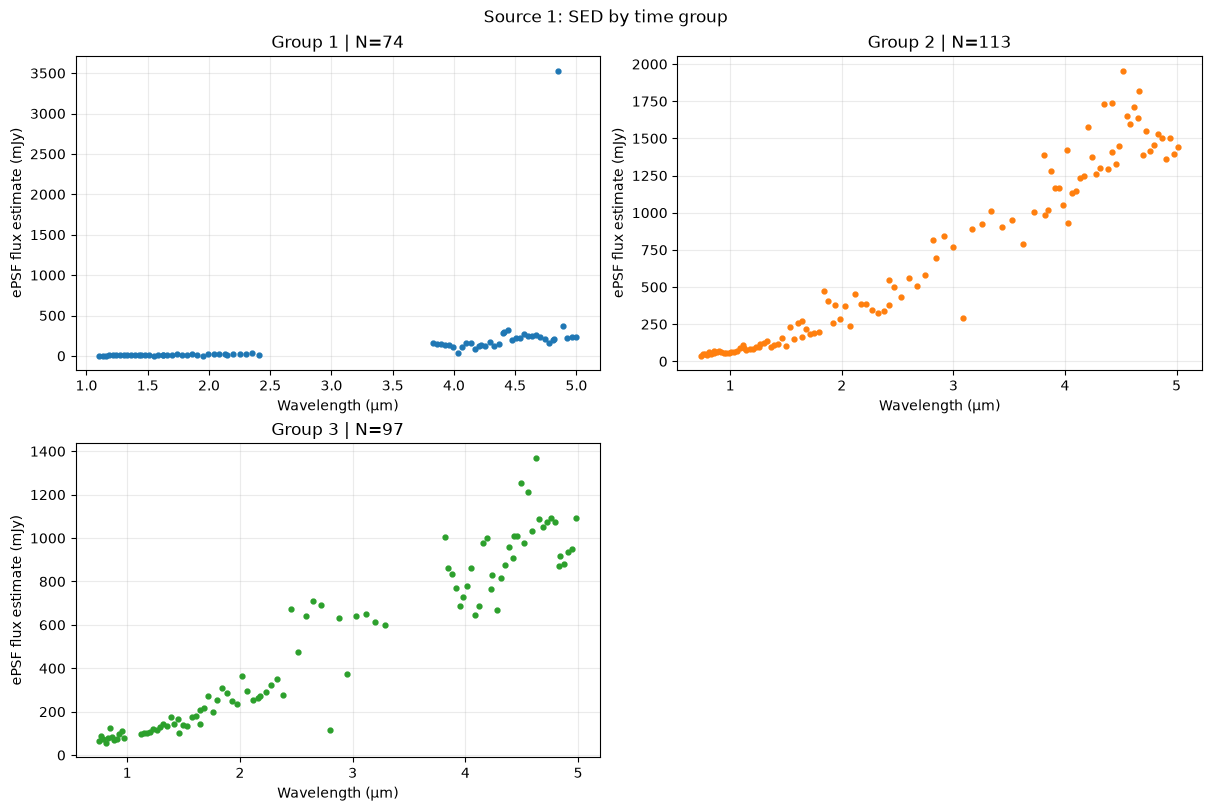

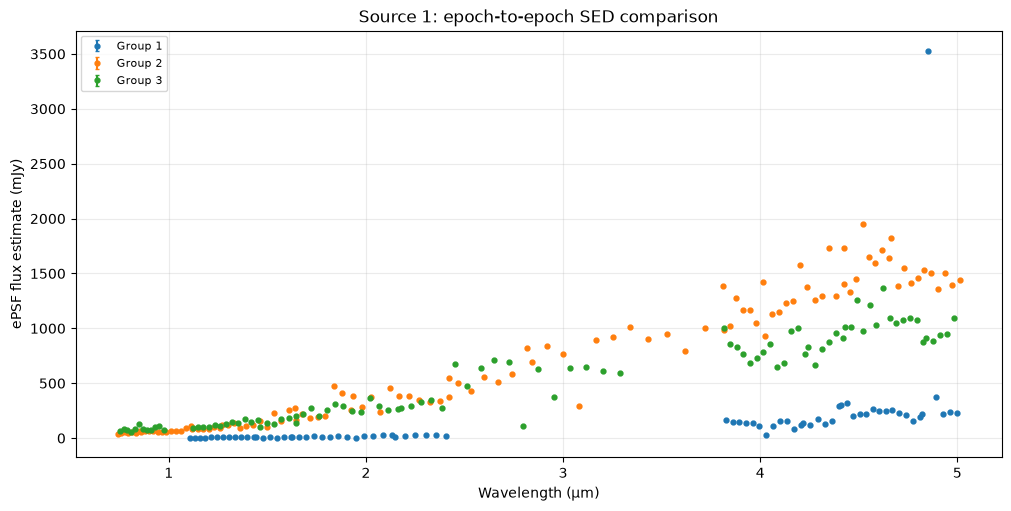

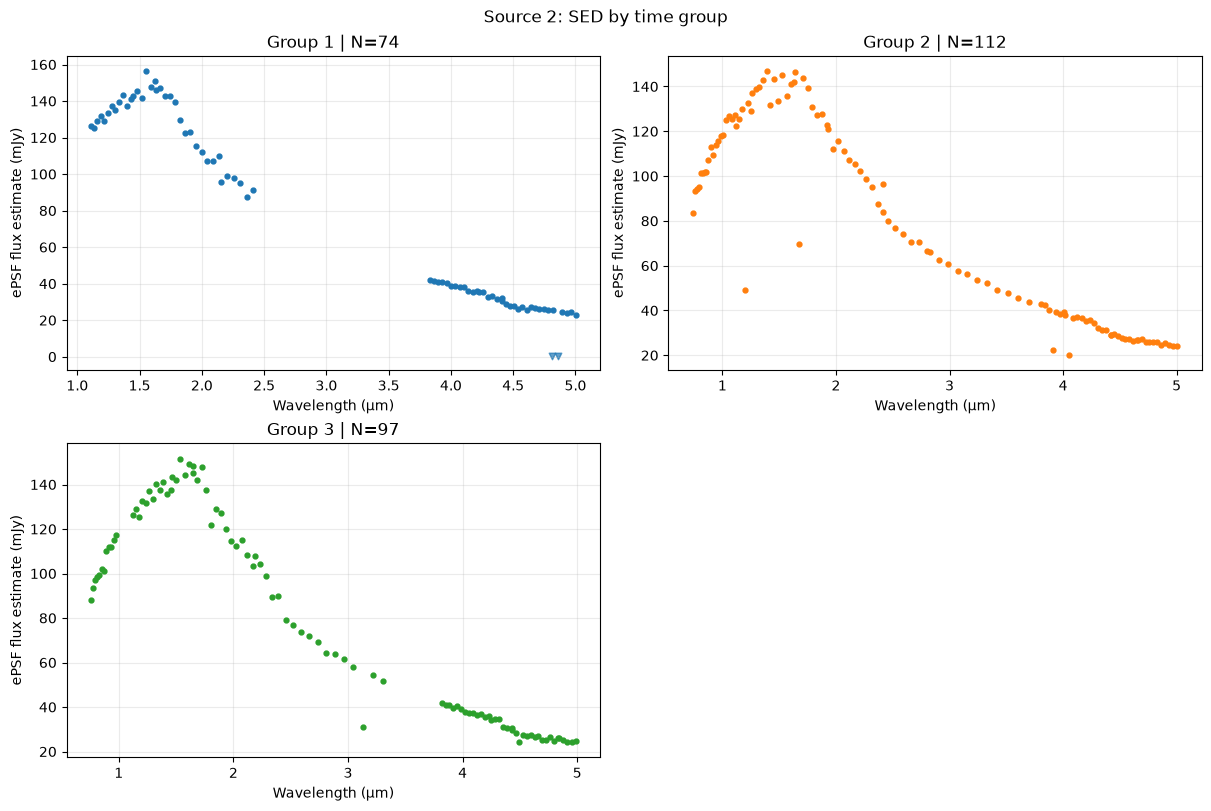

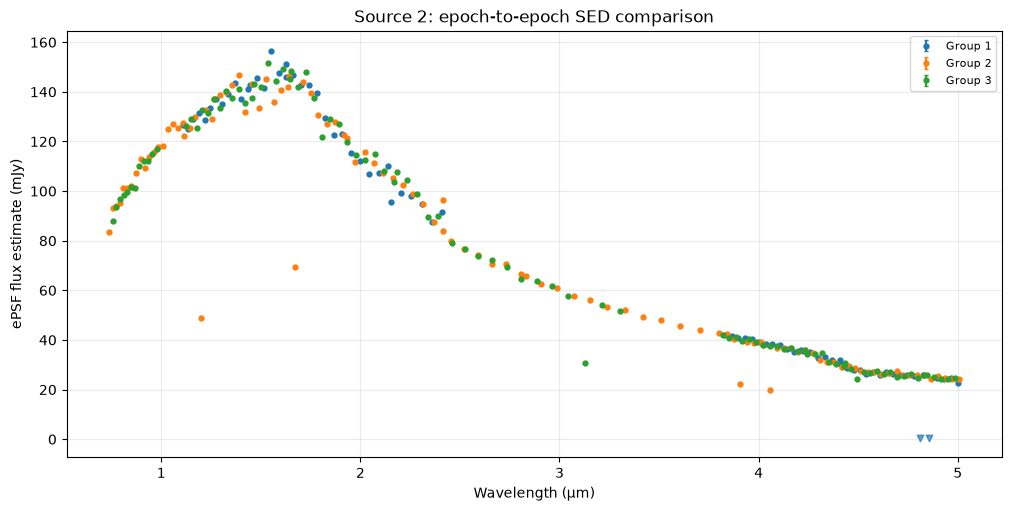

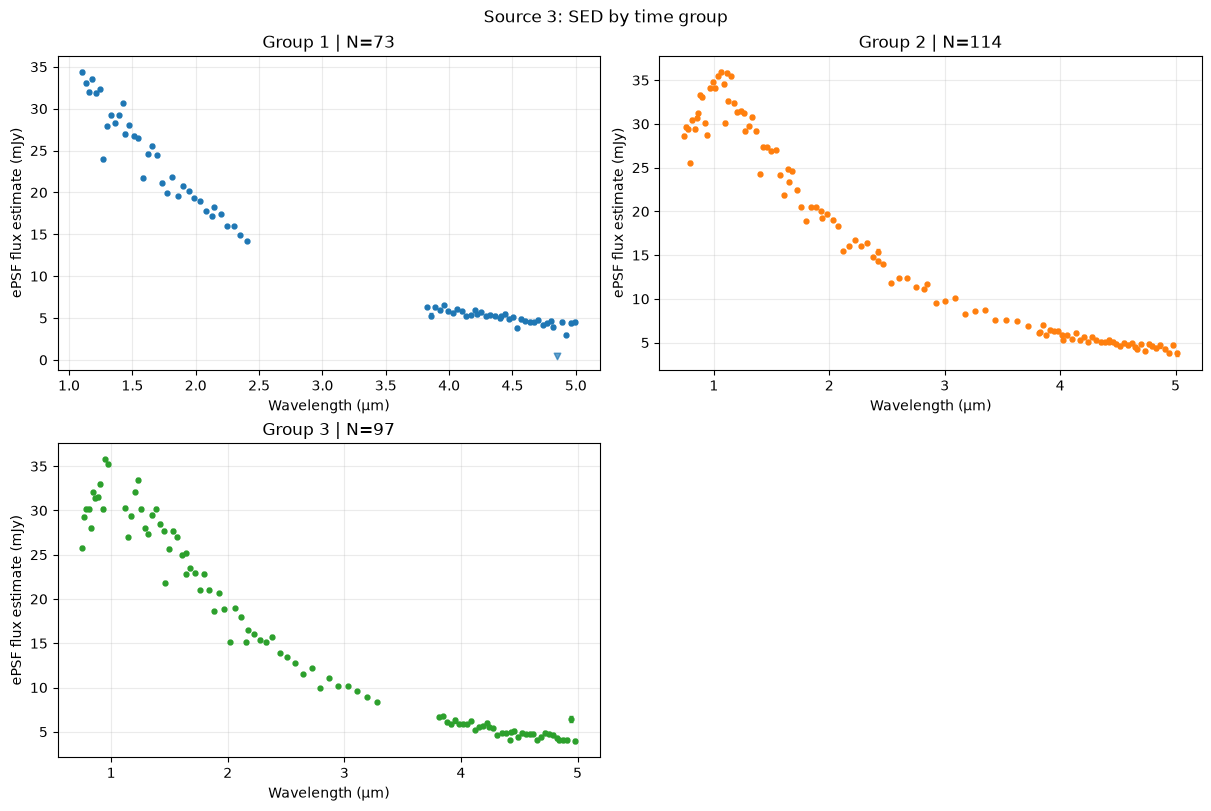

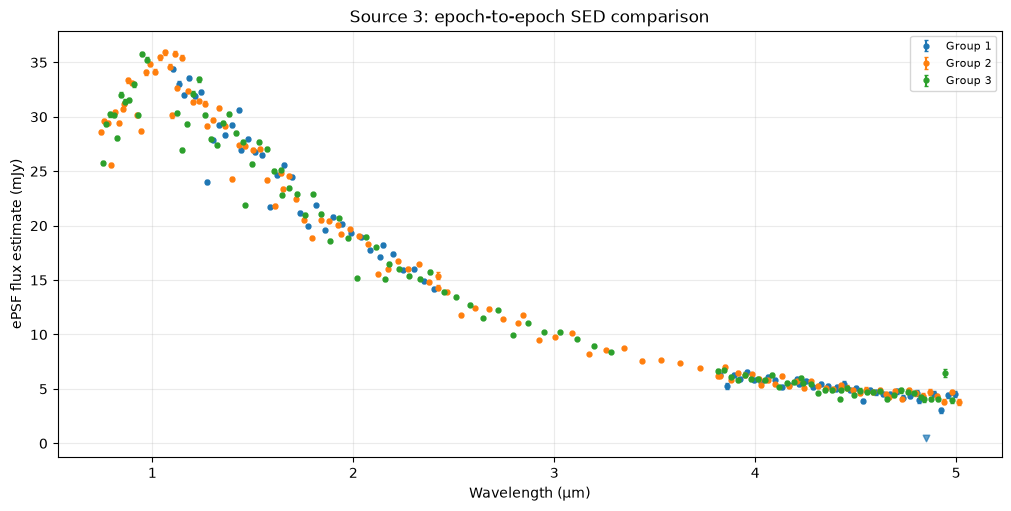

Saved SED plots in 6arcmin_spherex_targets/RW_Aurigae/analysis_runs/D5_D6_gap10_spaninf_v1/sed_plots


In [41]:
# Cell E - SED plots

PLOT_SOURCE_IDS = [s['source_id'] for s in sources]  # Set [1, 2, ...] to limit saving.
SHOW_FIRST_N = 3
PLOT_DIR = RUN_DIR / 'sed_plots'
PLOT_DIR.mkdir(exist_ok=True)

def plot_group_sed(ax, sub, color, label):
    if not len(sub):
        ax.text(0.5, 0.5, 'No measurements', transform=ax.transAxes, ha='center')
        return
    wavelength = np.asarray(sub['wavelength_um'], float)
    flux = np.asarray(sub['flux_mjy'], float)
    error = np.asarray(sub['fluxerr_mjy'], float)
    valid = np.isfinite(wavelength) & np.isfinite(flux) & np.isfinite(error) & (error > 0)
    detected = valid & (flux/error >= 3)
    limit = valid & ~detected
    if detected.any():
        order = np.argsort(wavelength[detected])
        ax.errorbar(wavelength[detected][order], flux[detected][order], yerr=error[detected][order], fmt='o', ms=3.5, capsize=1.5, color=color, label=label)
    if limit.any():
        ax.scatter(wavelength[limit], 3*error[limit], marker='v', color=color, s=22, alpha=0.7)
    ax.grid(alpha=0.25)
    ax.set_xlabel('Wavelength (µm)')
    ax.set_ylabel('ePSF flux estimate (mJy)')

for i, sid in enumerate(PLOT_SOURCE_IDS):
    rows = photometry[photometry['source_id'] == sid]
    if not len(rows):
        continue
    ncols = 2
    nrows = (len(group_ids)+ncols-1)//ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4*nrows), squeeze=False, constrained_layout=True)
    fig2, ax2 = plt.subplots(figsize=(10, 5), constrained_layout=True)
    for ax, gid in zip(axes.flat, group_ids):
        sub = rows[rows['group'] == gid]
        color = plt.get_cmap('tab10')((gid-1) % 10)
        plot_group_sed(ax, sub, color, f'Group {gid}')
        ax.set_title(f'Group {gid} | N={len(sub)}')
        if len(sub):
            plot_group_sed(ax2, sub, color, f'Group {gid}')
    for ax in list(axes.flat)[len(group_ids):]:
        ax.axis('off')
    fig.suptitle(f'Source {sid}: SED by time group')
    ax2.set_title(f'Source {sid}: epoch-to-epoch SED comparison')
    ax2.legend(loc='best', fontsize=8)
    fig.savefig(PLOT_DIR / f'source_{sid:03d}_group_sed.png', dpi=150)
    fig2.savefig(PLOT_DIR / f'source_{sid:03d}_sed_evolution.png', dpi=150)
    if i < SHOW_FIRST_N:
        plt.show()
    plt.close(fig)
    plt.close(fig2)
print('Saved SED plots in', PLOT_DIR)

In [ ]:
# Cell F1 - Build reliable cross-epoch astrometry from native ePSF fits
from collections import Counter, defaultdict
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.coordinates import SkyCoord
from astropy.table import Table
import astropy.units as u
import numpy as np

ASTRO_MIN_SNR = 8.0
ASTRO_MAX_CHI2RED = 8.0
MOVE_MIN_GROUPS = 3
MOVE_MIN_BASELINE_DAYS = 25.0
MOVE_MIN_DISPLACEMENT_PIX = 0.8
MOVE_MIN_SIGNIFICANCE = 4.0
MOVE_MAX_RMS_PIX = 0.7
ASTROMETRY_FLOOR_PIX = 0.25

with fits.open(OUTPUT_FITS, memmap=True) as h:
    gif_group_ids = sorted(int(x.name[5:]) for x in h if x.name.startswith('STACK') and x.name[5:].isdigit())
    stack_wcs = WCS(h[f'STACK{gif_group_ids[0]}'].header).celestial
    group_mjd = {g: (float(h[f'STACK{g}'].header['MJDSTART']) + float(h[f'STACK{g}'].header['MJDEND'])) / 2 for g in gif_group_ids}

pixel_scale_arcsec = float(np.mean(proj_plane_pixel_scales(stack_wcs)) * 3600)
make_key = lambda band, group, mjd: (str(band), int(group), round(float(mjd), 7))
record_counts = Counter(make_key(r['band'], r['group'], r['mjd']) for r in usable if int(r['group']) > 0)
phot_by_exposure = defaultdict(list)

for r in photometry:
    if np.isfinite(float(r['snr'])) and float(r['snr']) >= ASTRO_MIN_SNR and np.isfinite(float(r['chi2red'])) and float(r['chi2red']) <= ASTRO_MAX_CHI2RED:
        phot_by_exposure[make_key(r['band'], r['group'], r['mjd'])].append(r)

astrom = defaultdict(list)

for rec in usable:
    if int(rec['group']) <= 0:
        continue
    key = make_key(rec['band'], rec['group'], rec['mjd'])
    if record_counts[key] != 1 or key not in phot_by_exposure:
        continue  # A FITS path cannot be identified uniquely from (band, group, MJD).
    with fits.open(rec['path'], memmap=True) as hdul:
        image_wcs = WCS(hdul['IMAGE'].header).celestial
        rows = phot_by_exposure[key]
        xs = np.array([float(r['x']) for r in rows])
        ys = np.array([float(r['y']) for r in rows])
        ra, dec = image_wcs.pixel_to_world_values(xs, ys)
        stack_x, stack_y = stack_wcs.world_to_pixel_values(ra, dec)
        for r, x, y in zip(rows, stack_x, stack_y):
            if np.isfinite(x) and np.isfinite(y):
                astrom[(int(r['source_id']), int(r['group']))].append((float(r['mjd']), float(x), float(y)))

epoch_positions = defaultdict(list)

for (sid, gid), values in astrom.items():
    a = np.asarray(values, dtype=float)
    x0, y0 = np.median(a[:, 1]), np.median(a[:, 2])
    scatter = 1.4826 * np.median(np.hypot(a[:, 1] - x0, a[:, 2] - y0))
    position_error = max(ASTROMETRY_FLOOR_PIX, scatter / np.sqrt(len(a)))
    epoch_positions[sid].append(dict(group=gid, mjd=float(np.median(a[:, 0])), x=float(x0), y=float(y0), error_pix=float(position_error), n_images=len(a)))

moving_candidates = []

for sid, epochs in epoch_positions.items():
    epochs = sorted(epochs, key=lambda e: e['mjd'])
    if len(epochs) < MOVE_MIN_GROUPS:
        continue

    t_mjd = np.array([e['mjd'] for e in epochs])
    baseline = float(np.ptp(t_mjd))
    if baseline < MOVE_MIN_BASELINE_DAYS:
        continue

    t0 = float(np.mean(t_mjd))
    dt = (t_mjd - t0) / 365.25
    xy = np.array([[e['x'], e['y']] for e in epochs])
    invsig = 1 / np.array([e['error_pix'] for e in epochs])
    design = np.column_stack((np.ones_like(dt), dt))
    coef_x = np.linalg.lstsq(design * invsig[:, None], xy[:, 0] * invsig, rcond=None)[0]
    coef_y = np.linalg.lstsq(design * invsig[:, None], xy[:, 1] * invsig, rcond=None)[0]
    covariance = np.linalg.pinv((design * invsig[:, None]).T @ (design * invsig[:, None]))
    model = np.column_stack((design @ coef_x, design @ coef_y))
    residual_rms = float(np.sqrt(np.mean(np.sum((xy - model)**2, axis=1))))
    velocity_pix_yr = float(np.hypot(coef_x[1], coef_y[1]))
    displacement_pix = velocity_pix_yr * baseline / 365.25
    slope_error = float(np.sqrt(max(covariance[1, 1], 0)))
    significance = velocity_pix_yr / max(slope_error, 1e-12)

    if displacement_pix < MOVE_MIN_DISPLACEMENT_PIX or significance < MOVE_MIN_SIGNIFICANCE or residual_rms > MOVE_MAX_RMS_PIX:
        continue

    moving_candidates.append(dict(source_id=int(sid), n_groups=len(epochs), baseline_days=baseline, displacement_pix=displacement_pix, motion_arcsec_yr=velocity_pix_yr * pixel_scale_arcsec, motion_significance=significance, rms_pix=residual_rms, x0=float(coef_x[0]), y0=float(coef_y[0]), vx_pix_yr=float(coef_x[1]), vy_pix_yr=float(coef_y[1]), t0_mjd=t0))

moving_candidates.sort(key=lambda c: -c['motion_significance'])

print(f'Astrometry: {len(epoch_positions)} sources with high-SNR ePSF centroids; {len(moving_candidates)} moving candidates')

In [ ]:
# Cell F2 - Detect wavelength-matched variability and save candidate catalogs
from collections import defaultdict
from scipy.stats import chi2

VAR_WAVELENGTH_BIN_FRAC = 0.04  # Compare measurements within ~4% fractional wavelength bins.
VAR_ERROR_FLOOR_FRAC = 0.07    # Per-epoch systematic floor; tune after checking the data.
VAR_MAX_CHI2RED = 8.0
VAR_MIN_GROUPS = 3
VAR_FDR_Q = 0.01
VAR_MIN_PAIR_SIGMA = 4.0
VAR_MIN_FRACTIONAL_AMPLITUDE = 0.20

bins = defaultdict(list)

for r in photometry:
    sid, gid, band = int(r['source_id']), int(r['group']), str(r['band'])
    wave, flux, error = float(r['wavelength_um']), float(r['flux_mjy']), float(r['fluxerr_mjy'])
    quality = float(r['chi2red'])
    if not (gid > 0 and np.isfinite(wave) and wave > 0 and np.isfinite(flux) and np.isfinite(error) and error > 0 and np.isfinite(quality) and quality <= VAR_MAX_CHI2RED):
        continue
    wave_bin = int(np.floor(np.log(wave) / np.log1p(VAR_WAVELENGTH_BIN_FRAC)))
    bins[(sid, band, wave_bin, gid)].append((float(r['mjd']), wave, flux, error))

by_wave = defaultdict(list)

for (sid, band, wbin, gid), rows in bins.items():
    a = np.asarray(rows)
    weights = 1 / a[:, 3]**2
    avg_flux = float(np.sum(weights * a[:, 2]) / np.sum(weights))
    stat_error = float(np.sqrt(1 / np.sum(weights)))
    epoch_error = float(np.hypot(stat_error, VAR_ERROR_FLOOR_FRAC * abs(avg_flux)))
    by_wave[(sid, band, wbin)].append((gid, float(np.median(a[:, 0])), float(np.median(a[:, 1])), avg_flux, epoch_error))

var_tests = []

for (sid, band, wbin), epochs in by_wave.items():
    epochs.sort(key=lambda x: x[1])
    if len(epochs) < VAR_MIN_GROUPS:
        continue

    a = np.asarray(epochs, float)
    f, e = a[:, 3], a[:, 4]
    if np.max(f / e) < 5:
        continue

    w = 1 / e**2
    constant_flux = float(np.sum(w * f) / np.sum(w))
    stat = float(np.sum(((f - constant_flux) / e)**2))
    pvalue = float(chi2.sf(stat, len(f) - 1))
    pair_sig = max(float(abs(f[i]-f[j]) / np.hypot(e[i], e[j])) for i in range(len(f)) for j in range(i+1, len(f)))
    fraction = float(np.ptp(f) / max(abs(constant_flux), 3 * np.median(e)))
    var_tests.append(dict(source_id=sid, band=band, wavelength_um=float(np.median(a[:, 2])), n_groups=len(epochs), chi2=stat, pvalue=pvalue, pair_sigma=pair_sig, fractional_amplitude=fraction))

# Benjamini-Hochberg correction over all tested source/band/wavelength combinations.
if var_tests:
    p = np.array([v['pvalue'] for v in var_tests])
    order = np.argsort(p)
    qsorted = np.minimum.accumulate((p[order] * len(p) / np.arange(1, len(p)+1))[::-1])[::-1]
    qvalues = np.empty(len(p))
    qvalues[order] = np.minimum(qsorted, 1.0)
    for v, q in zip(var_tests, qvalues):
        v['qvalue'] = float(q)

variable_candidates = [v for v in var_tests if v['qvalue'] <= VAR_FDR_Q and v['pair_sigma'] >= VAR_MIN_PAIR_SIGMA and v['fractional_amplitude'] >= VAR_MIN_FRACTIONAL_AMPLITUDE]
variable_candidates.sort(key=lambda v: v['qvalue'])

move_columns = ['source_id', 'n_groups', 'baseline_days', 'displacement_pix', 'motion_arcsec_yr', 'motion_significance', 'rms_pix']
var_columns = ['source_id', 'band', 'wavelength_um', 'n_groups', 'chi2', 'pvalue', 'qvalue', 'pair_sigma', 'fractional_amplitude']

def write_candidates(records, columns, dtypes, path):
    table = Table(rows=[[r[col] for col in columns] for r in records], names=columns) if records else Table(names=columns, dtype=dtypes)
    table.write(path, format='ascii.ecsv', overwrite=True)
    return table

move_table = write_candidates(moving_candidates, move_columns, ['i4', 'i4'] + ['f8']*5, RUN_DIR / 'moving_candidates.ecsv')
var_table = write_candidates(variable_candidates, var_columns, ['i4', 'U24', 'f8', 'i4'] + ['f8']*5, RUN_DIR / 'variable_candidates.ecsv')

move_ids = {r['source_id'] for r in moving_candidates}
var_ids = {r['source_id'] for r in variable_candidates}
flagged_ids = sorted(move_ids | var_ids)
flagged = [dict(source_id=sid, classification=('M+V' if sid in move_ids and sid in var_ids else 'M' if sid in move_ids else 'V')) for sid in flagged_ids]
flagged_table = write_candidates(flagged, ['source_id', 'classification'], ['i4', 'U8'], RUN_DIR / 'flagged_sources.ecsv')

print(f'Variable candidates: {len(var_ids)} sources from {len(var_tests)} wavelength-matched tests; movers: {len(move_ids)}')
print(flagged_table if len(flagged_table) else 'No significant candidates with current thresholds')

In [ ]:
# Cell F3 - Animated, annotated time-group FITS stacks with movers and variables
from io import BytesIO
from PIL import Image
from IPython.display import display, Image as IPyImage
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Circle

MARKED_GIF = RUN_DIR / 'group_stacks_movers_variables.gif'
GIF_DURATION_MS = 900
GIF_MAX_ZOOMS = 4
GIF_ZOOM_HALF_WIDTH_PIX = 9
GIF_SHOW_ALL_IDS = True
GIF_ROTATE_180 = globals().get('ROTATE_180', False)

with fits.open(OUTPUT_FITS, memmap=True) as hdul:
    stack_images = {g: np.asarray(hdul[f'STACK{g}'].data, dtype=float).copy() for g in gif_group_ids}

movers_by_id = {m['source_id']: m for m in moving_candidates}
source_by_id = {int(s['source_id']): s for s in sources}
gif_candidates = sorted(flagged_ids, key=lambda sid: (sid not in move_ids, sid))
zoom_ids = []

for sid in list(sorted(move_ids)[:2]) + list(sorted(var_ids)[:2]) + gif_candidates:
    if sid not in zoom_ids and len(zoom_ids) < GIF_MAX_ZOOMS:
        zoom_ids.append(sid)

def get_source_xy(sid, gid):
    if sid in movers_by_id:
        m = movers_by_id[sid]
        dt = (group_mjd[gid] - m['t0_mjd']) / 365.25
        return m['x0'] + m['vx_pix_yr']*dt, m['y0'] + m['vy_pix_yr']*dt
    if (sid, gid) in positions_by_group:
        ra, dec = positions_by_group[(sid, gid)]
    else:
        ra, dec = source_by_id[sid]['ra'], source_by_id[sid]['dec']
    return stack_wcs.world_to_pixel_values(float(ra), float(dec))

zoom_settings = {}

for sid in zoom_ids:
    coords = np.asarray([get_source_xy(sid, g) for g in gif_group_ids], dtype=float)
    cx, cy = np.median(coords, axis=0)
    cutouts = []

    for im in stack_images.values():
        ny, nx = im.shape
        x1, x2 = max(0, int(cx)-GIF_ZOOM_HALF_WIDTH_PIX), min(nx, int(cx)+GIF_ZOOM_HALF_WIDTH_PIX+1)
        y1, y2 = max(0, int(cy)-GIF_ZOOM_HALF_WIDTH_PIX), min(ny, int(cy)+GIF_ZOOM_HALF_WIDTH_PIX+1)
        data = im[y1:y2, x1:x2]
        if np.isfinite(data).any():
            cutouts.append(data[np.isfinite(data)])

    vals = np.concatenate(cutouts) if cutouts else np.array([0.0, 1.0])
    vmin, vmax = np.percentile(vals, [5, 99.5])
    zoom_settings[sid] = (float(cx), float(cy), float(vmin), float(max(vmax, vmin+1e-9)))

all_finite = [im[np.isfinite(im)] for im in stack_images.values() if np.isfinite(im).any()]
if not all_finite:
    raise RuntimeError('All stacked images are empty; cannot create GIF')

full_vmin, full_vmax = np.percentile(np.concatenate(all_finite), [4, 99.5])
full_vmax = max(float(full_vmax), float(full_vmin) + 1e-9)
frames = []

for k, gid in enumerate(gif_group_ids, start=1):
    img = stack_images[gid]
    nzoom = max(1, len(zoom_ids))
    fig = plt.figure(figsize=(13.0, 7.2), facecolor='white')
    gs = fig.add_gridspec(nzoom, 2, width_ratios=[1.7, 1.0], wspace=0.15, hspace=0.30)
    ax = fig.add_subplot(gs[:, 0], projection=stack_wcs)

    ax.imshow(np.ma.masked_invalid(img), origin='lower', cmap='gray_r', vmin=full_vmin, vmax=full_vmax, interpolation='nearest')

    if GIF_SHOW_ALL_IDS:
        for (sid, group), (ra, dec) in positions_by_group.items():
            if group != gid:
                continue
            x, y = stack_wcs.world_to_pixel_values(ra, dec)
            if np.isfinite(x) and np.isfinite(y):
                ax.text(x+1.5, y+1.5, str(sid), color='gold', fontsize=7, path_effects=[pe.withStroke(linewidth=2, foreground='black')])

    for sid in flagged_ids:
        x, y = get_source_xy(sid, gid)
        if not (np.isfinite(x) and np.isfinite(y)):
            continue

        if sid in move_ids:
            m = movers_by_id[sid]
            history = np.linspace(min(group_mjd.values()), group_mjd[gid], 25)
            hx = m['x0'] + m['vx_pix_yr'] * (history - m['t0_mjd']) / 365.25
            hy = m['y0'] + m['vy_pix_yr'] * (history - m['t0_mjd']) / 365.25
            ax.plot(hx, hy, '-', color='red', linewidth=1.6, alpha=0.9)
            ax.add_patch(Circle((x, y), 3, fill=False, edgecolor='red', linewidth=1.7))

        if sid in var_ids:
            ax.add_patch(Circle((x, y), 4.6 if sid in move_ids else 3, fill=False, edgecolor='cyan', linewidth=1.5))

        ax.text(x+3, y-3, f'{sid}: {"M+V" if sid in move_ids and sid in var_ids else "M" if sid in move_ids else "V"}', color='red' if sid in move_ids else 'darkcyan', fontsize=9, weight='bold', path_effects=[pe.withStroke(linewidth=2, foreground='white')])

    if GIF_ROTATE_180:
        ax.set_xlim(img.shape[1] - 0.5, -0.5)
        ax.set_ylim(img.shape[0] - 0.5, -0.5)

    ax.set_xlabel('RA')
    ax.set_ylabel('Dec')
    ax.set_title(f'{TARGET_TO_ANALYZE} | Group {gid} ({k}/{len(gif_group_ids)}) | MJD {group_mjd[gid]:.2f}')

    for j in range(nzoom):
        az = fig.add_subplot(gs[j, 1])

        if j >= len(zoom_ids):
            az.text(0.5, 0.5, 'No candidates at current thresholds', transform=az.transAxes, ha='center', va='center')
            az.axis('off')
            continue

        sid = zoom_ids[j]
        cx, cy, zmin, zmax = zoom_settings[sid]
        az.imshow(np.ma.masked_invalid(img), origin='lower', cmap='gray_r', vmin=zmin, vmax=zmax, interpolation='nearest')
        az.set_xlim(cx - GIF_ZOOM_HALF_WIDTH_PIX, cx + GIF_ZOOM_HALF_WIDTH_PIX)
        az.set_ylim(cy - GIF_ZOOM_HALF_WIDTH_PIX, cy + GIF_ZOOM_HALF_WIDTH_PIX)

        if GIF_ROTATE_180:
            az.invert_xaxis()
            az.invert_yaxis()

        x, y = get_source_xy(sid, gid)

        if sid in move_ids:
            m = movers_by_id[sid]
            history = np.linspace(min(group_mjd.values()), group_mjd[gid], 25)
            az.plot(m['x0'] + m['vx_pix_yr']*(history-m['t0_mjd'])/365.25, m['y0'] + m['vy_pix_yr']*(history-m['t0_mjd'])/365.25, '-', color='red', linewidth=2)
            az.add_patch(Circle((x, y), 2.2, fill=False, edgecolor='red', linewidth=1.7))

        if sid in var_ids:
            az.add_patch(Circle((x, y), 3.1 if sid in move_ids else 2.2, fill=False, edgecolor='cyan', linewidth=1.7))

        az.set_title(f'Source {sid} | {"M+V" if sid in move_ids and sid in var_ids else "M" if sid in move_ids else "V"}', fontsize=10)
        az.set_xticks([])
        az.set_yticks([])

    fig.text(0.54, 0.01, f'Red: moving candidate | Cyan: variable candidate | {len(move_ids)} movers, {len(var_ids)} variables', ha='center', fontsize=9)

    buffer = BytesIO()
    fig.savefig(buffer, format='png', dpi=110, facecolor='white')
    plt.close(fig)
    buffer.seek(0)

    with Image.open(buffer) as frame:
        frames.append(frame.convert('RGB').copy())

palette = frames[0].quantize(colors=256)
quantized = [frame.quantize(palette=palette) for frame in frames]
quantized[0].save(MARKED_GIF, save_all=True, append_images=quantized[1:], duration=GIF_DURATION_MS, loop=0, optimize=False, disposal=2)

print(f'Saved: {MARKED_GIF} | frames={len(frames)}')
display(IPyImage(filename=str(MARKED_GIF)))